In [ ]:
''' 
This Notebook produces a SOTA LSTM models for RUL for the FD001 CMAPSS Dataset
'''

import requests
import zipfile
from pathlib import Path

url = "https://data.nasa.gov/docs/legacy/CMAPSSData.zip"

data_dir = Path("data")
data_dir.mkdir(exist_ok=True)

# Download the data set from NASA
response = requests.get(url, timeout=120)
response.raise_for_status()

zip_path = data_dir / "CMAPSSData.zip"
zip_path.write_bytes(response.content)

# Extract the dataset
with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(data_dir)

print("Dataset downloaded and extracted!")


Dataset downloaded and extracted!


In [ ]:
import pandas as pd
from pathlib import Path

# now we save the data into a Pandas data fram 
# Define all 26 columns in the data se
columns = (["unit_id", "cycle"] + [f"setting_{i}" for i in range(1, 4)] + [f"sensor_{i}" for i in range(1, 22)])

# Find the extracted files
data_dir = Path("data")

train_path = next(data_dir.rglob("train_FD001.txt"))
test_path = next(data_dir.rglob("test_FD001.txt"))
rul_path = next(data_dir.rglob("RUL_FD001.txt"))

# Load training and testing data
train_df = pd.read_csv(
    train_path,
    sep=r"\s+",
    header=None,
    names=columns
)

test_df = pd.read_csv(
    test_path,
    sep=r"\s+",
    header=None,
    names=columns
)

# Ground-truth RUL for each test engine
rul_df = pd.read_csv(
    rul_path,
    sep=r"\s+",
    header=None,
    names=["RUL"]
)

print(train_df.head())
print(train_df.shape)

   unit_id  cycle  setting_1  setting_2  setting_3  sensor_1  sensor_2  \
0        1      1    -0.0007    -0.0004      100.0    518.67    641.82   
1        1      2     0.0019    -0.0003      100.0    518.67    642.15   
2        1      3    -0.0043     0.0003      100.0    518.67    642.35   
3        1      4     0.0007     0.0000      100.0    518.67    642.35   
4        1      5    -0.0019    -0.0002      100.0    518.67    642.37   

   sensor_3  sensor_4  sensor_5  ...  sensor_12  sensor_13  sensor_14  \
0   1589.70   1400.60     14.62  ...     521.66    2388.02    8138.62   
1   1591.82   1403.14     14.62  ...     522.28    2388.07    8131.49   
2   1587.99   1404.20     14.62  ...     522.42    2388.03    8133.23   
3   1582.79   1401.87     14.62  ...     522.86    2388.08    8133.83   
4   1582.85   1406.22     14.62  ...     522.19    2388.04    8133.80   

   sensor_15  sensor_16  sensor_17  sensor_18  sensor_19  sensor_20  sensor_21  
0     8.4195       0.03        392 

In [ ]:
# Find failure cycle of each training engine
max_cycles = train_df.groupby("unit_id")["cycle"].transform("max")

# Calculate RUL and add to the data frame
train_df["RUL"] = max_cycles - train_df["cycle"]

print(train_df[["unit_id", "cycle", "RUL"]].head())

   unit_id  cycle  RUL
0        1      1  191
1        1      2  190
2        1      3  189
3        1      4  188
4        1      5  187


In [4]:
# One row per engine: the final available measurement
test_final = (
    test_df.sort_values(["unit_id", "cycle"])
    .groupby("unit_id")
    .tail(1)
    .sort_values("unit_id")
    .reset_index(drop=True)
)

# Add true test RUL
assert len(test_final) == len(rul_df)
test_final["RUL"] = rul_df["RUL"]

print(test_final[["unit_id", "cycle", "RUL"]].head())

   unit_id  cycle  RUL
0        1     31  112
1        2     49   98
2        3    126   69
3        4    106   82
4        5     98   91


unit_id      0
cycle        0
setting_1    0
setting_2    0
setting_3    0
sensor_1     0
sensor_2     0
sensor_3     0
sensor_4     0
sensor_5     0
sensor_6     0
sensor_7     0
sensor_8     0
sensor_9     0
sensor_10    0
sensor_11    0
sensor_12    0
sensor_13    0
sensor_14    0
sensor_15    0
sensor_16    0
sensor_17    0
sensor_18    0
sensor_19    0
sensor_20    0
sensor_21    0
RUL          0
dtype: int64
sensor_19    0.000000e+00
sensor_18    0.000000e+00
sensor_16    1.556432e-14
sensor_10    4.660829e-13
sensor_5     3.394700e-12
sensor_1     6.537152e-11
sensor_6     1.388985e-03
sensor_15    3.750504e-02
sensor_8     7.098548e-02
sensor_13    7.191892e-02
sensor_21    1.082509e-01
sensor_20    1.807464e-01
sensor_11    2.670874e-01
sensor_2     5.000533e-01
sensor_12    7.375534e-01
sensor_7     8.850923e-01
sensor_17    1.548763e+00
sensor_3     6.131150e+00
sensor_4     9.000605e+00
sensor_14    1.907618e+01
sensor_9     2.208288e+01
dtype: float64


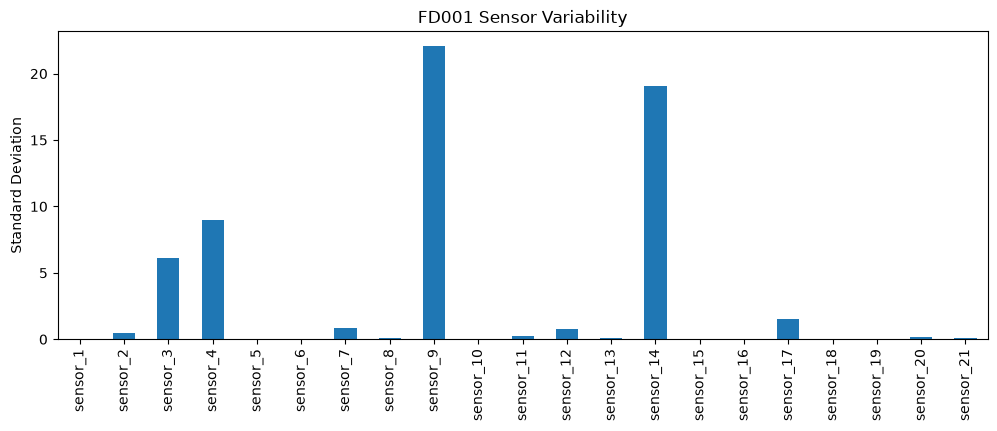

In [6]:
import matplotlib.pyplot as plt

sensor_cols = [f"sensor_{i}" for i in range(1, 22)]

# Check missing values
print(train_df.isnull().sum())

# Examine sensor variability
sensor_std = train_df[sensor_cols].std()

print(sensor_std.sort_values())

# Visualize sensor standard deviations
sensor_std.plot(kind="bar", figsize=(12, 4))
plt.ylabel("Standard Deviation")
plt.title("FD001 Sensor Variability")
plt.show()

In [7]:
# only some of the sensors change so we use them for training 
selected_sensors = [
    "sensor_2", "sensor_3", "sensor_4",
    "sensor_7", "sensor_8", "sensor_9",
    "sensor_11", "sensor_12", "sensor_13",
    "sensor_14", "sensor_15", "sensor_17",
    "sensor_20", "sensor_21"
]

from sklearn.model_selection import train_test_split

# Get unique engine identifiers
engine_ids = train_df["unit_id"].unique()

# 80% training engines, 20% validation engines
train_ids, val_ids = train_test_split(
    engine_ids,
    test_size=0.2,
    random_state=42,
    shuffle=True
)

# Create separate datasets
train_data = train_df[
    train_df["unit_id"].isin(train_ids)
].copy()

val_data = train_df[
    train_df["unit_id"].isin(val_ids)
].copy()

print("Training engines:", train_data["unit_id"].nunique())
print("Validation engines:", val_data["unit_id"].nunique())

Training engines: 80
Validation engines: 20


In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

# For most machine learning applciations we normalize our data
# Fit using training engines only
train_data[selected_sensors] = scaler.fit_transform(
    train_data[selected_sensors]
)

# Apply the same transformation to validation engines
val_data[selected_sensors] = scaler.transform(
    val_data[selected_sensors]
)

# Normalize test data with the same scaler
test_data = test_df.copy()

test_data[selected_sensors] = scaler.transform(
    test_data[selected_sensors]
)

In [10]:
import numpy as np
def create_sequences(df, features, window_size=50):
    """
    Generate fixed-length sequences for LSTM training.

    Each sequence belongs to one engine.
    Its label is the RUL at its final cycle.
    """
    X, y = [], []

    for engine_id, engine in df.groupby("unit_id"):
        engine = engine.sort_values("cycle")

        sensor_data = engine[features].to_numpy(
            dtype=np.float32
        )
        rul_data = engine["RUL"].to_numpy(
            dtype=np.float32
        )

        for end in range(window_size, len(engine) + 1):
            start = end - window_size

            X.append(sensor_data[start:end])
            y.append(rul_data[end - 1])

    return (
        np.asarray(X, dtype=np.float32),
        np.asarray(y, dtype=np.float32)
    )

WINDOW_SIZE = 50

X_train, y_train = create_sequences(
    train_data,
    selected_sensors,
    WINDOW_SIZE
)

X_val, y_val = create_sequences(
    val_data,
    selected_sensors,
    WINDOW_SIZE
)

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_val:", X_val.shape)
print("y_val:", y_val.shape)

def create_test_sequences(df, features, window_size=50):
    X = []

    for engine_id, engine in df.groupby("unit_id"):
        engine = engine.sort_values("cycle")

        sensor_data = engine[features].to_numpy(
            dtype=np.float32
        )

        # Take last 50 cycles
        sequence = sensor_data[-window_size:]

        # Pad shorter trajectories using their first observation
        if len(sequence) < window_size:
            padding = np.repeat(
                sequence[:1],
                window_size - len(sequence),
                axis=0
            )
            sequence = np.vstack([padding, sequence])

        X.append(sequence)

    return np.asarray(X, dtype=np.float32)


X_test = create_test_sequences(
    test_data,
    selected_sensors,
    WINDOW_SIZE
)

# Test labels correspond to the final cycle of each engine
y_test = rul_df["RUL"].to_numpy(dtype=np.float32)

assert len(X_test) == len(y_test)

print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

X_train: (12641, 50, 14)
y_train: (12641,)
X_val: (3090, 50, 14)
y_val: (3090,)
X_test: (100, 50, 14)
y_test: (100,)


In [12]:
import torch
from torch.utils.data import TensorDataset, DataLoader

BATCH_SIZE = 64

train_dataset = TensorDataset(
    torch.from_numpy(X_train),
    torch.from_numpy(y_train)
)

val_dataset = TensorDataset(
    torch.from_numpy(X_val),
    torch.from_numpy(y_val)
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Number of training batches:", len(train_loader))
print("Number of validation batches:", len(val_loader))

Number of training batches: 198
Number of validation batches: 49
